# 21 Pretraining: does NTU60 skeleton pretraining help the ST-GCN?

**Why this test.** Stages 1 to 3 of model 5 (notebooks 18 to 20) found nothing in the architecture or the loss that
beats the plain ST-GCN with velocity input on validation. The one lever left with a clear mechanism is pretraining:
Li et al. (2024) describe fine tuning from pretrained weights, and a network trained on 40,000 NTU60 action clips has
seen far more skeleton motion than our 6,247 training clips. This is a separate experiment from model 5's
components, so that any gain is not credited to velocity or to the head.

**The checkpoint.** mmaction2's `stgcn_8xb16-joint-u100-80e_ntu60-xsub-keypoint-2d`, from the config stored inside
the file: the default ST-GCN with 10 blocks on the 17 joint COCO layout, input channels (x, y, confidence) as joint
coordinates, 100 frame clips, 60 classes, 16 epochs over a dataset repeated 5 times (80 epochs in all), SGD with
learning rate 0.1 at batch size 128. Our paper configuration has 9 blocks, so layer by layer loading is not possible.
The pretrained arms therefore use the 10 block layout, and a 10 block model trained from scratch is the control that
separates the effect of the layout from the effect of the weights.

**What transfers** (see `models/pretrained.py`). Every convolution, temporal convolution and batch norm tensor except
the input batch norm (it describes NTU coordinates and has a different shape), the first layer's input weights (3
input channels there, 9 here) and the 60 class head. The adjacency matrices are loaded too, after the smoke test
checks they equal ours.

| arm | layout | weights | first layer | backbone learning rate |
|---|---|---|---|---|
| `control9` | 9 blocks | scratch | n/a | the stage 1 control, **reused**, for reference only |
| `scratch10` | 10 blocks | scratch | n/a | full |
| `pre_xy` | 10 blocks | NTU60 | x, y, confidence weights copied, our extra channels start at zero | full |
| `pre_free` | 10 blocks | NTU60 | re-initialised | full |
| `pre_xy_lowlr` | 10 blocks | NTU60 | as `pre_xy` | 0.1 times (first layer, input batch norm and head stay at full) |

**Input note.** The checkpoint saw coordinates normalised around the image centre, while ours are centred on the hip
and scaled by body height, so what the copied first layer weights mean is only approximately the same. The input
batch norm restarts, which standardises each joint and channel in our own units. `pre_xy` and `pre_free` test whether
copying that first layer helps or whether letting it relearn is better.

**Protocol.** Validation only, seeds 77 and 88 (as in the earlier stages), same recipe as the ST-GCN (SGD learning rate
0.01, weight decay 5e-3, step schedule, advanced augmentation, balanced sampler, cross entropy), velocity input as in
model 5. The pretraining recipe used weight decay 5e-4, ten times smaller than ours; the tuned weight decay may pull
pretrained weights away faster than ideal, which `pre_xy_lowlr` partly probes.

**Decision rule, fixed before running.** A pretrained arm counts as helping if its mean validation top 1 is at least
0.5 points above `scratch10` and its mean validation MCA is not more than 1 point lower than `scratch10`. The best
qualifying arm is chosen, preferring fewer changes within 0.3 points; if none qualify, pretraining is reported as not
helping. `control9` is shown for reference so that the effect of the layout is visible, and is not part of the rule.

Logs to `BadmintonPoseAnalysis/experiments/pretraining`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
NTU_CHECKPOINT = os.environ.get("NTU_CHECKPOINT", "/workspace/checkpoints/stgcn_ntu60_pretrained/stgcn_ntu60.pth")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
from models import pretrained
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/pretraining"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/pretraining"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")          # the test set is never evaluated while tuning
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))
MIN_GAIN, MAX_MCA_DROP, TIE = 0.005, 0.01, 0.003
LOW_LR_FACTOR = 0.1
FULL_LR_PREFIXES = ("backbone.data_bn", "backbone.gcn.0.gcn.conv", "cls_head")     # new or reshaped, never slowed down

ARMS = {                           # trained arms
    "scratch10":    {"stages": 10, "first_layer": None, "low_lr": False},
    "pre_xy":       {"stages": 10, "first_layer": "xy", "low_lr": False},
    "pre_free":     {"stages": 10, "first_layer": "free", "low_lr": False},
    "pre_xy_lowlr": {"stages": 10, "first_layer": "xy", "low_lr": True},
}
ORDER = ["control9", *ARMS]
REFERENCE, PRETRAINED = "scratch10", ["pre_xy", "pre_free", "pre_xy_lowlr"]
N_CHANGES = {"scratch10": 0, "pre_xy": 1, "pre_free": 1, "pre_xy_lowlr": 2}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
with open(f"{REPO}/configs/model5_stage1.json") as f:
    STAGE1 = json.load(f)
BACKBONE, VEL_SCALE = STAGE1["backbone_options"], STAGE1["velocity_scale"]
assert os.path.exists(NTU_CHECKPOINT), NTU_CHECKPOINT

In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train = manifest[manifest["split"] == "train"].reset_index(drop=True)
train_counts = train["class_name"].value_counts().reindex(class_names)
rare_ids = [class_to_id[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]
common_ids = [k for k in range(K) if k not in rare_ids]

in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)
forward = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)


def build(spec):
    model = stgcn_model.build_stgcn(in_channels, K, stages=spec["stages"], **BACKBONE)
    report = pretrained.load_ntu60(model, NTU_CHECKPOINT, spec["first_layer"]) if spec["first_layer"] else None
    return model, report


def optimiser_for(model, low_lr):
    if not low_lr:
        params = model.parameters()
    else:
        full = [p for n, p in model.named_parameters() if n.startswith(FULL_LR_PREFIXES)]
        slow = [p for n, p in model.named_parameters() if not n.startswith(FULL_LR_PREFIXES)]
        params = [{"params": full, "lr": RECIPE["lr"]}, {"params": slow, "lr": RECIPE["lr"] * LOW_LR_FACTOR}]
    return torch.optim.SGD(params, lr=RECIPE["lr"], momentum=RECIPE["momentum"], weight_decay=RECIPE["weight_decay"])

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Run alone first. It checks what the transfer actually did before any training time is spent: every checkpoint tensor
must be accounted for (loaded, or skipped for a stated reason), the adjacency matrices must equal ours, the copied first
layer must hold the pretrained weights for channels 0 to 2 and zeros elsewhere, and every arm must run a forward and
backward pass. If the graph check fails the two models do not share a graph definition and the transfer is not
meaningful.

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
batch = next(iter(loaders["train"]))
source = torch.load(NTU_CHECKPOINT, map_location="cpu")["state_dict"]
ntu_backbone = {k: v for k, v in source.items() if k.startswith("backbone.")}

rows = []
for arm, spec in ARMS.items():
    model, report = build(spec)
    params = sum(p.numel() for p in model.parameters())
    if report is not None:
        assert not report["unexpected_skips"], f"{arm}: unexpected skipped tensors {report['unexpected_skips'][:5]}"
        assert report["graph_max_difference"] < 1e-5, f"{arm}: adjacency differs from the checkpoint by {report['graph_max_difference']}"
        assert all(k.startswith(("backbone.data_bn.", "cls_head.", "backbone.gcn.0.gcn.conv.weight")) for k in report["not_loaded_model_keys"]), \
            report["not_loaded_model_keys"][:5]
        if spec["first_layer"] == "xy":
            w = model.state_dict()[pretrained.FIRST_CONV]
            assert torch.equal(w[:, :3], source[pretrained.FIRST_CONV][:, :3]) and not w[:, 3:].any(), "first layer copy is wrong"
    model.to(device)
    loss = nn.CrossEntropyLoss()(forward(model, batch, device), batch["label"].to(device))
    assert torch.isfinite(loss)
    loss.backward()
    assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    groups = optimiser_for(model, spec["low_lr"]).param_groups
    rows.append({"arm": arm, "blocks": spec["stages"], "parameters": params,
                 "tensors loaded": report["loaded_tensors"] if report else 0,
                 "values loaded": report["loaded_values"] if report else 0,
                 "skipped": len(report["skipped"]) if report else 0,
                 "graph max diff": report["graph_max_difference"] if report else np.nan,
                 "lr groups": " / ".join(f"{len(g['params'])} tensors at {g['lr']:g}" for g in groups),
                 "first batch loss": round(loss.item(), 3)})
    del model
print(pd.DataFrame(rows).to_string(index=False))
print(f"checkpoint backbone: {len(ntu_backbone)} tensors, {sum(v.numel() for v in ntu_backbone.values()):,} values")

control = pd.read_csv(f"{STAGE1_OUT}/results.csv")
control = control[control["config"] == "control"]
assert sorted(control["seed"]) == sorted(SEEDS)
del loaders
print("smoke test passed")

         arm  blocks  parameters  tensors loaded  values loaded  skipped  graph max diff                               lr groups  first batch loss
   scratch10      10     3079266               0              0        0             NaN                     102 tensors at 0.01             3.212
      pre_xy      10     3079266             174        3089426        7    5.960464e-08                     102 tensors at 0.01             2.911
    pre_free      10     3079266             173        3087698        8    5.960464e-08                     102 tensors at 0.01             2.846
pre_xy_lowlr      10     3079266             174        3089426        7    5.960464e-08 6 tensors at 0.01 / 96 tensors at 0.001             2.853
checkpoint backbone: 179 tensors, 3,088,479 values
smoke test passed


## Runs

Four arms, two seeds each, eight runs. Results are appended after every run and finished runs are skipped. The
transfer report of each pretrained run is stored with its metrics.

In [5]:
results_path = f"{OUT}/results.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


def run_arm(name, spec, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    run_name = f"pretrain_{name}_s{seed}"
    print(f"\n=== {run_name}  {spec} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["pretraining", name, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    model, report = build(spec)
    task.connect({**RECIPE, "arm": name, **spec, "low_lr_factor": LOW_LR_FACTOR, "checkpoint": NTU_CHECKPOINT,
                  "backbone_options": BACKBONE, "input": "body_court_velocity", "in_channels": in_channels,
                  "velocity_scale": VEL_SCALE, "seed": seed, "keypoints": KEYPOINTS, "split_sha256": split_hash,
                  "evaluated_splits": list(SPLITS)})
    if report is not None:
        task.connect({"loaded_tensors": report["loaded_tensors"], "loaded_values": report["loaded_values"],
                      "skipped": [f"{k}: {why}" for k, why in report["skipped"]],
                      "graph_max_difference": report["graph_max_difference"]}, name="transfer")

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
    model = model.to(device)
    optimizer = optimiser_for(model, spec["low_lr"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed, "stages": spec["stages"],
                                   "first_layer": str(spec["first_layer"]), "low_lr": spec["low_lr"]})
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


for name, spec in ARMS.items():
    for seed in SEEDS:
        run_arm(name, spec, seed)


=== pretrain_scratch10_s77  {'stages': 10, 'first_layer': None, 'low_lr': False} ===
ClearML Task: created new task id=e45515a1ddc042da820ad1cd3f5ae842
2026-10-07 06:36:14,529 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/2906b9ac8fa146dbb1132d273d4e6bb3/tasks/e45515a1ddc042da820ad1cd3f5ae842/output/log
epoch   0  loss 1.957  train 0.565  val 0.551 (mca 0.457)  *
epoch   1  loss 1.483  train 0.607  val 0.611 (mca 0.463)  *
epoch   2  loss 1.331  train 0.657  val 0.640 (mca 0.524)  *
epoch   4  loss 1.219  train 0.675  val 0.657 (mca 0.579)  *
epoch   5  loss 1.206  train 0.683  val 0.673 (mca 0.557)  *
epoch   7  loss 1.150  train 0.690  val 0.682 (mca 0.609)  *
epoch  10  loss 0.909  train 0.782  val 0.726 (mca 0.641)  *
epoch  12  loss 0.755  train 0.811  val 0.727 (mca 0.631)  *
epoch  14  loss 0.690  train 0.836  val 0.732 (mca 0.630)  *
epoch  15  loss 0.656  train 0.823  val 0.716 (mca 0.

███████████████████████████████ 100% | 11.87/11.87 MB [00:01<00:00,  7.54MB/s]: 



=== pretrain_scratch10_s88  {'stages': 10, 'first_layer': None, 'low_lr': False} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=91b88d6d4d4a4d65a89c32c0dd6c1f3b
ClearML results page: https://app.clear.ml/projects/2906b9ac8fa146dbb1132d273d4e6bb3/tasks/91b88d6d4d4a4d65a89c32c0dd6c1f3b/output/log
epoch   0  loss 1.938  train 0.519  val 0.538 (mca 0.441)  *
epoch   1  loss 1.510  train 0.547  val 0.539 (mca 0.448)  *
epoch   2  loss 1.386  train 0.631  val 0.633 (mca 0.491)  *
epoch   4  loss 1.245  train 0.701  val 0.686 (mca 0.577)  *
epoch   5  loss 1.206  train 0.693  val 0.667 (mca 0.582)
epoch   6  loss 1.174  train 0.693  val 0.690 (mca 0.604)  *
epoch  10  loss 0.926  train 0.775  val 0.726 (mca 0.638)  *
epoch  11  loss 0.823  train 0.783  val 0.731 (mca 0.648)  *
epoch  15  loss 0.671  train 0.829  val 0.718 (mca 0.640)
epoch  20  loss 0.478  train 0.898  val 0.744 (mca 0.650)  *
epoch  21  loss 0.432  train 0.904  val 0.745 (mca 0.655)  *
epoch  25  loss 0.372  train 0.929  val 0.743 (mca 0.638)
epoch  30  loss 0.310  train 0.949  val 0.740 (mca 0.641)
epoch  32  loss 0

...

███████████████████████████████ 100% | 11.87/11.87 MB [00:01<00:00,  6.26MB/s]: 



=== pretrain_pre_xy_lowlr_s88  {'stages': 10, 'first_layer': 'xy', 'low_lr': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=dd898507b33f40dea7ef21d8eefe423f
ClearML results page: https://app.clear.ml/projects/2906b9ac8fa146dbb1132d273d4e6bb3/tasks/dd898507b33f40dea7ef21d8eefe423f/output/log
epoch   0  loss 1.634  train 0.613  val 0.574 (mca 0.537)  *
epoch   1  loss 1.076  train 0.708  val 0.653 (mca 0.586)  *
epoch   2  loss 0.860  train 0.814  val 0.691 (mca 0.612)  *
epoch   5  loss 0.526  train 0.884  val 0.685 (mca 0.589)
epoch   8  loss 0.393  train 0.926  val 0.700 (mca 0.585)  *
epoch  10  loss 0.198  train 0.989  val 0.718 (mca 0.619)  *
epoch  11  loss 0.124  train 0.994  val 0.729 (mca 0.623)  *
epoch  12  loss 0.111  train 0.997  val 0.732 (mca 0.621)  *
epoch  15  loss 0.076  train 0.999  val 0.732 (mca 0.622)
epoch  16  loss 0.074  train 1.000  val 0.738 (mca 0.628)  *
epoch  20  loss 0.056  train 1.000  val 0.734 (mca 0.621)
epoch  25  loss 0.056  train 1.000  val 0.736 (mca 0.624)
epoch  27  loss 0.053  train 1.000  val 0.739 (mca 0.630)  *
epoch  30  loss 0

███████████████████████████████ 100% | 11.87/11.87 MB [00:01<00:00,  6.01MB/s]: 


## Selection

Mean over the two seeds, validation only. The rule compares each pretrained arm with `scratch10`; `control9` is the
stage 1 control (9 blocks, from scratch), shown to see what the layout alone does.

In [6]:
def val_recall(path):
    p = pd.read_csv(path)
    p = p[p["split"] == "val"]
    labels, preds = p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy()
    rec = np.array([(preds[labels == k] == k).mean() for k in range(K)])
    return rec[rare_ids].mean(), rec[common_ids].mean()


def run_dir(arm, seed):
    return (f"{STAGE1_OUT}/model5s1_control_s{seed}/model5s1_control_s{seed}" if arm == "control9"
            else f"{OUT}/pretrain_{arm}_s{seed}/pretrain_{arm}_s{seed}")


results = pd.concat([control.assign(config="control9"), load_results()], ignore_index=True)
results["limited_recall"], results["common_recall"] = zip(*[val_recall(f"{run_dir(r.config, r.seed)}_predictions.csv")
                                                          for r in results.itertuples()])
g = results.groupby("config")
table = pd.DataFrame({
    "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
    "val top5": g["val_top5"].mean(), "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
    "limited recall": g["limited_recall"].mean(), "common recall": g["common_recall"].mean(),
    "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(),
    "parameters": g["parameters"].first(), "seeds": g["seed"].count(),
}).loc[ORDER]
ref = table.loc[REFERENCE]
table["d top1"] = table["val top1"] - ref["val top1"]
table["d mca"] = table["val mca"] - ref["val mca"]
table["passes"] = [(n in PRETRAINED) and (r["d top1"] >= MIN_GAIN) and (r["d mca"] >= -MAX_MCA_DROP) for n, r in table.iterrows()]

eligible = [REFERENCE] + [n for n in PRETRAINED if table.loc[n, "passes"]]
best = table.loc[eligible, "val top1"].max()
close = [n for n in eligible if best - table.loc[n, "val top1"] <= TIE]
selected = min(close, key=lambda n: (N_CHANGES[n], -table.loc[n, "val top1"]))
print("pretrained arms passing the rule:", [n for n in PRETRAINED if table.loc[n, "passes"]] or "none")
print("selected:", selected if selected != REFERENCE else "none, pretraining is not reported as helping")

pct = ["val top1", "val top1 std", "val top5", "val mca", "val macro f1", "limited recall", "common recall",
       "train val gap", "d top1", "d mca"]
show = table.assign(**{c: (100 * table[c]).round(2) for c in pct}).round({"best epoch": 1})
show["selected"] = [n == selected and n != REFERENCE for n in show.index]
show

pretrained arms passing the rule: none
selected: none, pretraining is not reported as helping


,val top1,val top1 std,val top5,val mca,val macro f1,limited recall,common recall,train val gap,best epoch,parameters,seeds,d top1,d mca,passes,selected
config,,,,,,,,,,,,,,,
control9,76.76,0.45,95.20,67.75,68.22,61.55,72.71,20.02,34.5,3028735.0,2,1.28,2.97,False,False
scratch10,75.48,0.63,94.88,64.79,65.20,57.63,70.51,20.31,34.0,3079266.0,2,0.00,0.00,False,False
pre_xy,75.16,0.18,94.56,65.03,66.36,58.06,70.60,24.84,47.0,3079266.0,2,-0.32,0.24,False,False
pre_free,73.82,1.00,94.94,64.19,65.41,57.89,69.22,21.89,18.5,3079266.0,2,-1.66,-0.60,False,False
pre_xy_lowlr,74.14,0.00,93.79,63.31,64.77,56.02,69.15,25.86,32.0,3079266.0,2,-1.34,-1.47,False,False


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=985e7d9a81b34f248cc9fb0c87826a67
ClearML results page: https://app.clear.ml/projects/2906b9ac8fa146dbb1132d273d4e6bb3/tasks/985e7d9a81b34f248cc9fb0c87826a67/output/log


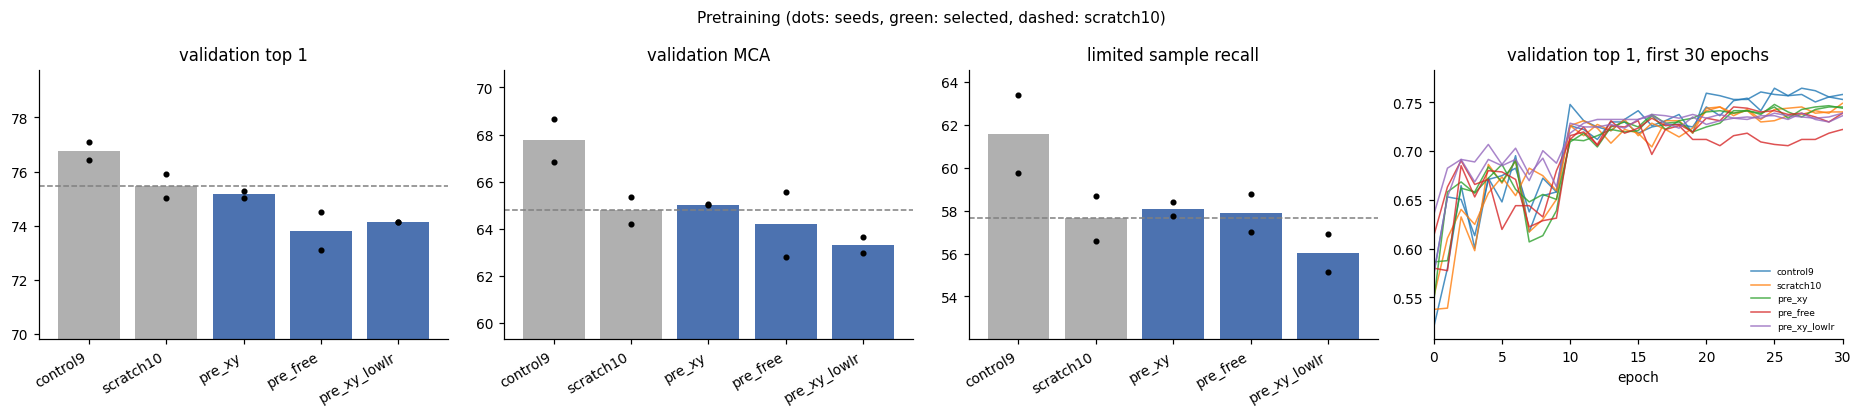

In [7]:
task = Task.init(project_name=PROJECT, task_name="pretraining_selection", task_type=Task.TaskTypes.qc,
                 tags=["pretraining", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({**RECIPE, "arms": ARMS, "seeds": SEEDS, "checkpoint": NTU_CHECKPOINT, "velocity_scale": VEL_SCALE,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP, "tie": TIE, "reference": REFERENCE}})
slog.report_table("pretraining comparison (validation, mean over tuning seeds)", "val", iteration=0,
                  table_plot=show.reset_index().rename(columns={"index": "arm"}))
slog.report_single_value("selected_val_top1", float(table.loc[selected, "val top1"]))
slog.report_single_value("reference_val_top1", float(ref["val top1"]))

colour_of = lambda n: "#55a868" if (n == selected and n != REFERENCE) else "#b0b0b0" if n in ("control9", REFERENCE) else "#4c72b0"
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
x = np.arange(len(ORDER))
for ax, metric, title in zip(axes[:3], ["val_top1", "val_mca", "limited_recall"],
                             ["validation top 1", "validation MCA", "limited sample recall"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in ORDER]
    ax.bar(x, 100 * np.array(means), color=[colour_of(n) for n in ORDER])
    for i, n in enumerate(ORDER):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.axhline(100 * results.loc[results["config"] == REFERENCE, metric].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, ORDER, rotation=30, ha="right")
    ax.set_ylim(100 * min(means) - 4, 100 * max(means) + 3)
    ax.set_title(title)
for n, colour in zip(ORDER, plt.cm.tab10.colors):               # how fast each arm learns
    for i, s in enumerate(SEEDS):
        c = pd.read_csv(f"{run_dir(n, s)}_history.csv")
        axes[3].plot(c["epoch"], c["val_top1"], color=colour, lw=1, alpha=0.8, label=n if i == 0 else None)
axes[3].set_xlim(0, 30)
axes[3].set_title("validation top 1, first 30 epochs")
axes[3].set_xlabel("epoch")
axes[3].legend(frameon=False, fontsize=6)
fig.suptitle("Pretraining (dots: seeds, green: selected, dashed: scratch10)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("pretraining comparison", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

In [8]:
decision = {"experiment": "ntu60_pretraining", "pretraining_helps": selected != REFERENCE,
            "selected": None if selected == REFERENCE else selected,
            "spec": None if selected == REFERENCE else {**ARMS[selected], "low_lr_factor": LOW_LR_FACTOR},
            "checkpoint": NTU_CHECKPOINT, "reference": REFERENCE,
            "tuning": {"seeds": SEEDS, "selected_val_top1": round(float(table.loc[selected, "val top1"]), 4),
                       "selected_val_mca": round(float(table.loc[selected, "val mca"]), 4),
                       "scratch10_val_top1": round(float(ref["val top1"]), 4), "scratch10_val_mca": round(float(ref["val mca"]), 4),
                       "control9_val_top1": round(float(table.loc["control9", "val top1"]), 4)}}
with open(f"{REPO}/configs/pretraining.json", "w") as f:
    json.dump(decision, f, indent=2)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/pretraining.json")
task.upload_artifact("results", artifact_object=results_path)
task.close()
decision

{'experiment': 'ntu60_pretraining',
 'pretraining_helps': False,
 'selected': None,
 'spec': None,
 'checkpoint': '/workspace/checkpoints/stgcn_ntu60_pretrained/stgcn_ntu60.pth',
 'reference': 'scratch10',
 'tuning': {'seeds': [77, 88],
  'selected_val_top1': 0.7548,
  'selected_val_mca': 0.6479,
  'scratch10_val_top1': 0.7548,
  'scratch10_val_mca': 0.6479,
  'control9_val_top1': 0.7676}}

## Reading the result

- Read the rule's outcome against `scratch10`, not `control9`. If `scratch10` differs from `control9` by about a
  point or less, the 10 block layout is not what is being measured and the comparison is clean.
- If a pretrained arm passes, the gain is a candidate for the final five seed comparison, reported as with and without
  pretraining for both the plain ST-GCN and the velocity model, so it is not credited to either. Two seeds cannot
  separate differences under about a point.
- Compare `pre_xy` with `pre_free`. If copying the first layer helps, the pretrained x, y filters are usable despite
  the different coordinate frame; if not, the first layer is better learned from scratch.
- Look at the learning curves, not only the endpoint. Pretraining can give a much faster start without changing where
  training ends, which is worth reporting even when the final difference is inside the noise.
- If nothing passes, fine tuning from NTU60 does not help on this dataset with this recipe. That does not rule out
  Li et al.'s own gain from pretraining: their pretraining source, input representation and fine tuning recipe are not
  specified in enough detail to reproduce it.